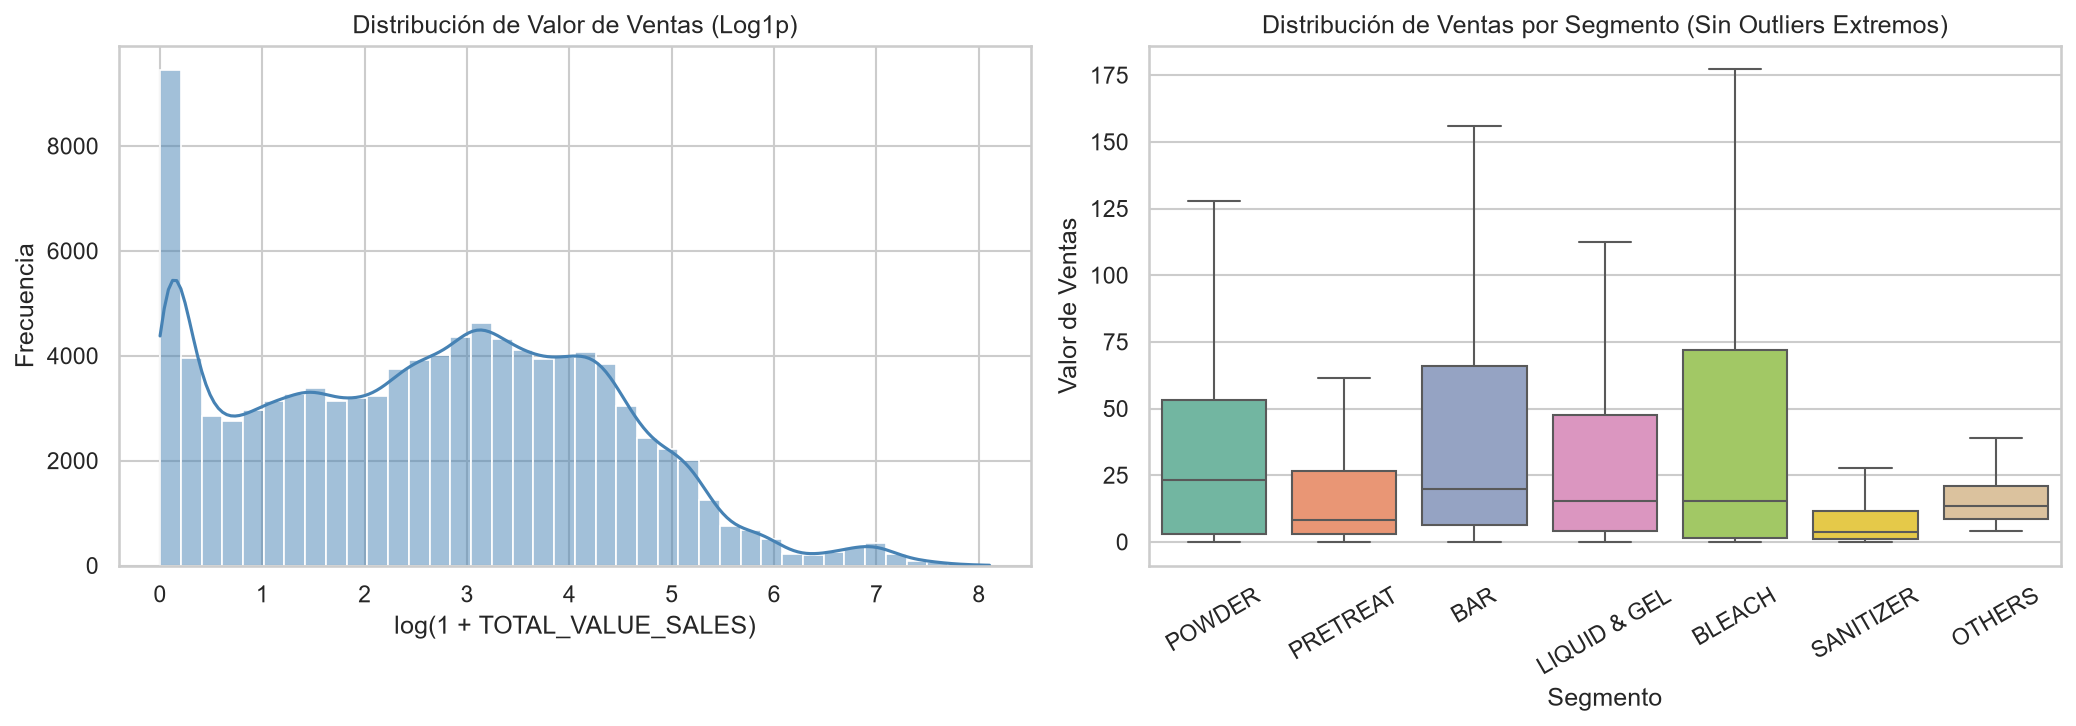

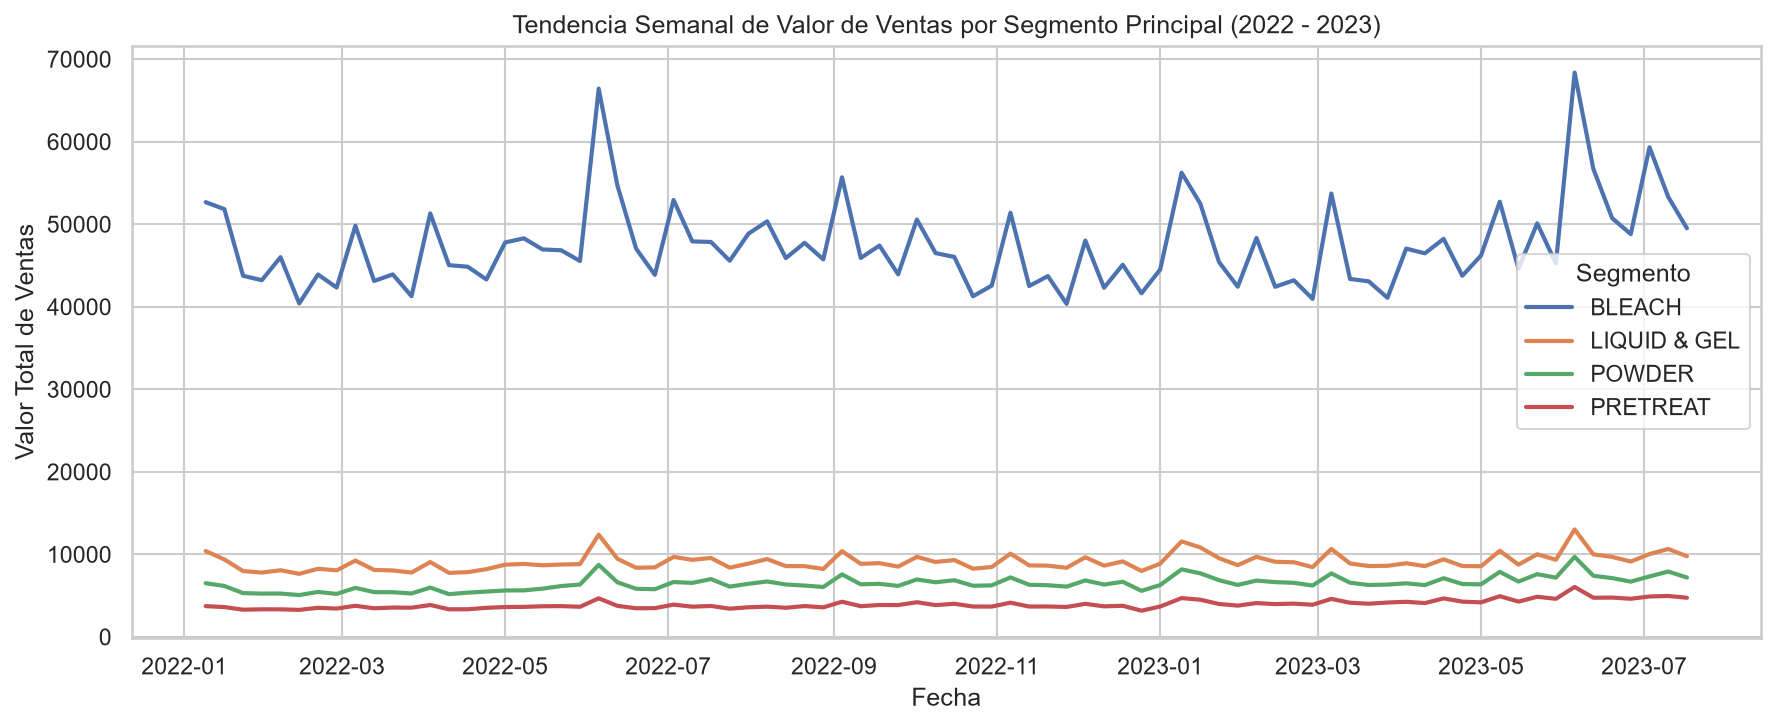

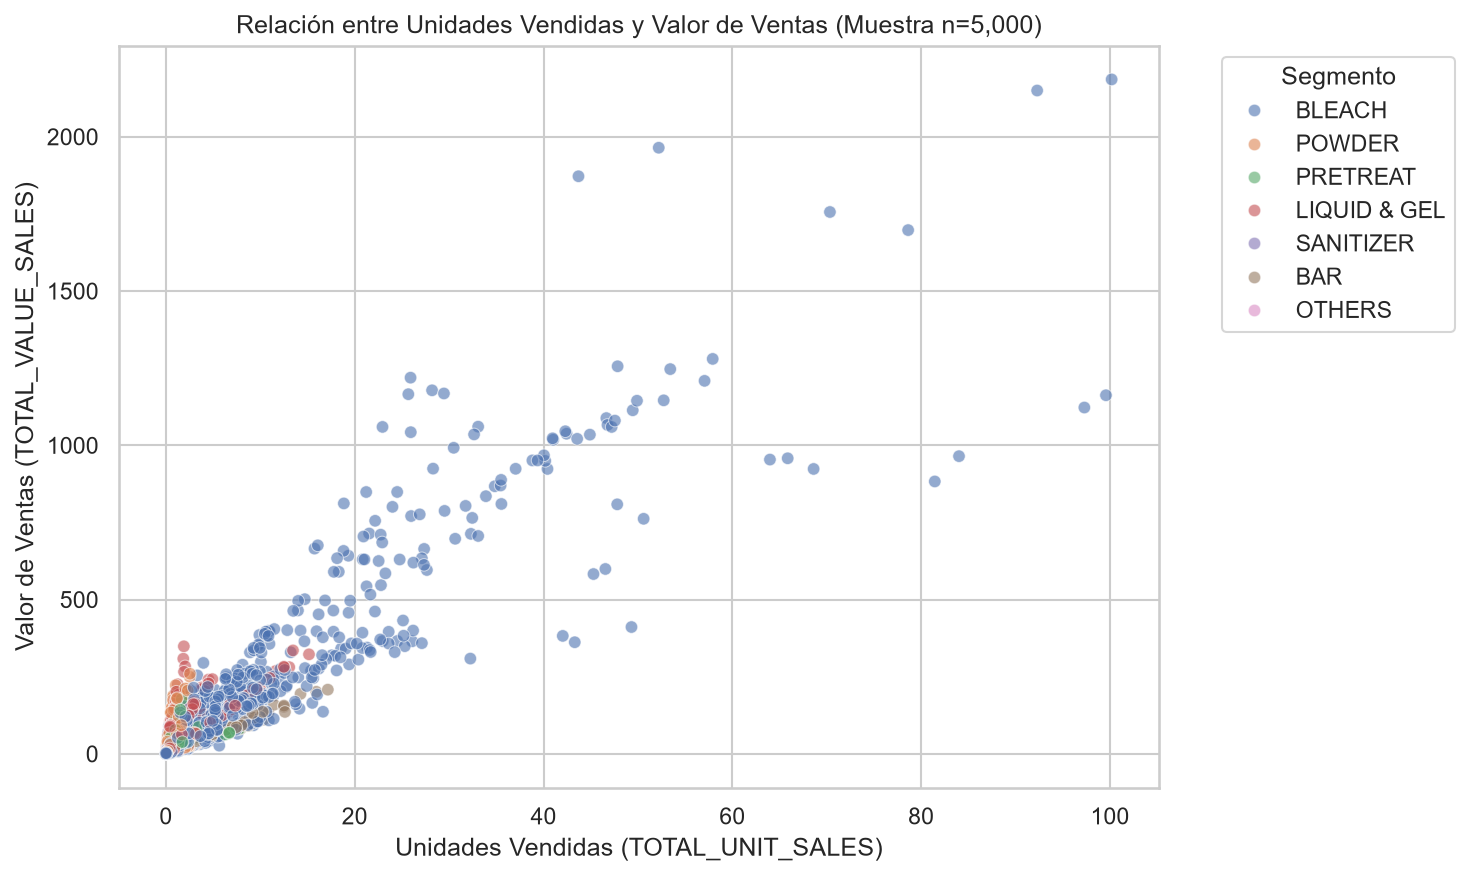

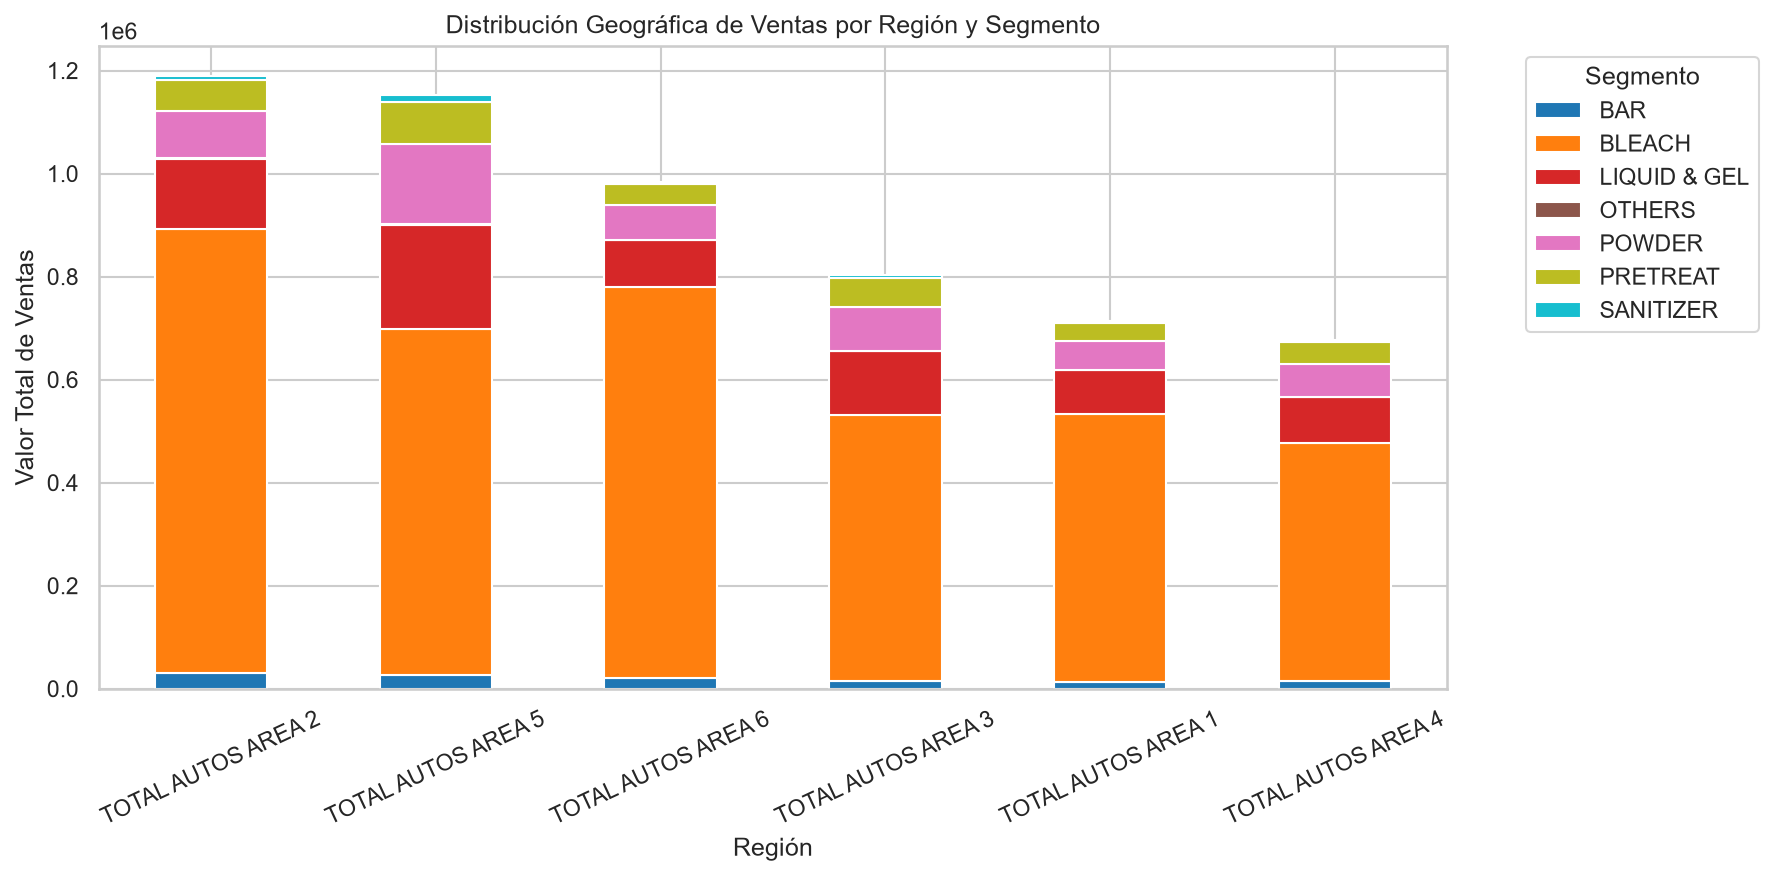

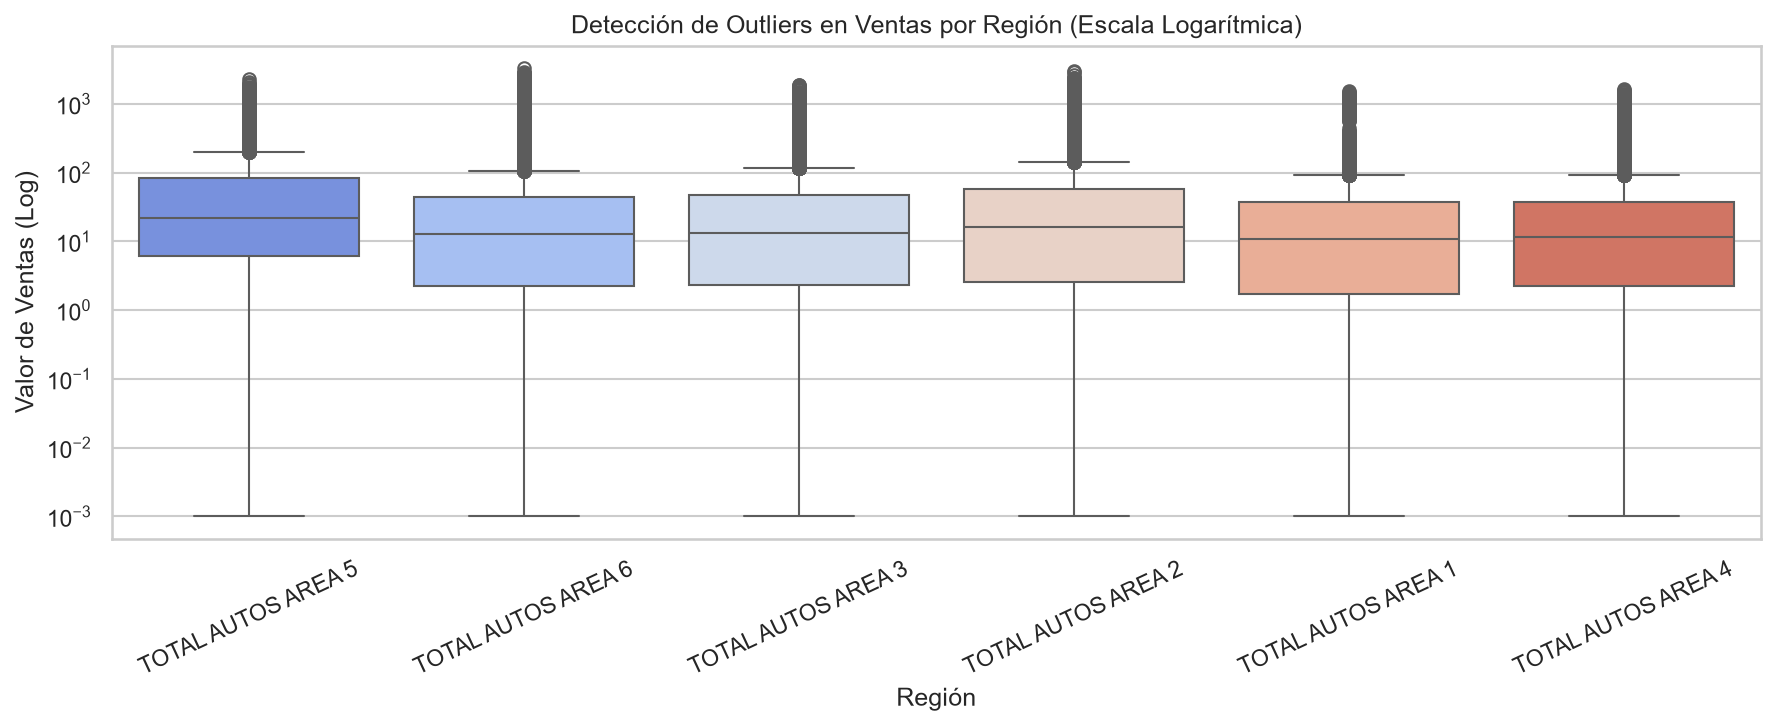

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

sales = pd.read_csv('FACT_SALES.csv')
cal = pd.read_excel('DIM_CALENDAR.xlsx', sheet_name='Sheet1')
cat = pd.read_csv('DIM_CATEGORY.csv')
prod = pd.read_excel('DIM_PRODUCT.xlsx', sheet_name='Sheet1')
seg = pd.read_excel('DIM_SEGMENT.xlsx', sheet_name='SEGMENT')

cat['CATEGORY'] = cat['CATEGORY'].str.strip()
prod['ITEM'] = prod['ITEM'].astype(str).str.strip()
sales['ITEM_CODE'] = sales['ITEM_CODE'].astype(str).str.strip()

df = (sales
      .merge(cal, on='WEEK', how='left')
      .merge(prod, left_on='ITEM_CODE', right_on='ITEM', how='left')
      .merge(cat, left_on='CATEGORY', right_on='ID_CATEGORY', how='left', suffixes=('', '_NAME'))
      .merge(seg, on=['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT'], how='left'))

df_reg = df[df['REGION'] != 'TOTAL AUTOS SCANNING MEXICO'].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(np.log1p(df_reg['TOTAL_VALUE_SALES']), bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribución de Valor de Ventas (Log1p)')
axes[0].set_xlabel('log(1 + TOTAL_VALUE_SALES)')
axes[0].set_ylabel('Frecuencia')

sns.boxplot(data=df_reg, x='SEGMENT', y='TOTAL_VALUE_SALES', hue='SEGMENT', ax=axes[1], showfliers=False, palette='Set2', legend=False)
axes[1].set_title('Distribución de Ventas por Segmento (Sin Outliers Extremos)')
axes[1].set_xlabel('Segmento')
axes[1].set_ylabel('Valor de Ventas')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('1_distribucion_ventas.png', dpi=300)
plt.show()

top_segs = ['BLEACH', 'LIQUID & GEL', 'POWDER', 'PRETREAT']
df_time = df_reg[df_reg['SEGMENT'].isin(top_segs)].groupby(['DATE', 'SEGMENT'])['TOTAL_VALUE_SALES'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=df_time, x='DATE', y='TOTAL_VALUE_SALES', hue='SEGMENT', linewidth=2)
plt.title('Tendencia Semanal de Valor de Ventas por Segmento Principal (2022 - 2023)')
plt.xlabel('Fecha')
plt.ylabel('Valor Total de Ventas')
plt.legend(title='Segmento')
plt.tight_layout()
plt.savefig('2_tendencia_tiempo.png', dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
sample_df = df_reg.sample(n=5000, random_state=42)
sns.scatterplot(data=sample_df, x='TOTAL_UNIT_SALES', y='TOTAL_VALUE_SALES', hue='SEGMENT', alpha=0.6)
plt.title('Relación entre Unidades Vendidas y Valor de Ventas (Muestra n=5,000)')
plt.xlabel('Unidades Vendidas (TOTAL_UNIT_SALES)')
plt.ylabel('Valor de Ventas (TOTAL_VALUE_SALES)')
plt.legend(title='Segmento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('3_relacion_variables.png', dpi=300)
plt.show()

pivot_reg = df_reg.pivot_table(index='REGION', columns='SEGMENT', values='TOTAL_VALUE_SALES', aggfunc='sum', fill_value=0)
pivot_reg = pivot_reg.loc[pivot_reg.sum(axis=1).sort_values(ascending=False).index]

pivot_reg.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab10')
plt.title('Distribución Geográfica de Ventas por Región y Segmento')
plt.xlabel('Región')
plt.ylabel('Valor Total de Ventas')
plt.xticks(rotation=25)
plt.legend(title='Segmento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('4_distribucion_geografica.png', dpi=300)
plt.show()

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_reg, x='REGION', y='TOTAL_VALUE_SALES', hue='REGION', palette='coolwarm', legend=False)
plt.yscale('log')
plt.title('Detección de Outliers en Ventas por Región (Escala Logarítmica)')
plt.xlabel('Región')
plt.ylabel('Valor de Ventas (Log)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig('5_outliers_regiones.png', dpi=300)
plt.show()

In [ ]:
# prueba commit en VS Code

In [ ]:
# prueba en branch